# RQ2 — Trade-off fedeltà / privacy

**Domanda di ricerca (RQ2):** *C'è un trade-off tra somiglianza statistica (fedeltà) dei dati sintetici e rischio privacy?*

Questo notebook confronta, per ciascuna combinazione **dataset × metodo di generazione** (`GaussianCopulaSynthesizer` vs `CTGANSynthesizer`), due assi:

- **Fedeltà**: `overall_quality_score` (SDMetrics `evaluate_quality`) — quanto le distribuzioni e le correlazioni del dataset sintetico somigliano a quelle del dataset reale. 1.0 = fedeltà massima.
- **Rischio privacy**, misurato in due modi indipendenti:
  - **NewRowSynthesis (NRS)**: stima la % di righe sintetiche che sono effettivamente "nuove" (non quasi-copie di righe reali). Un valore **basso** indica che il synthesizer tende a rigenerare record già visti → rischio più alto. Definiamo `rischio_NRS = 1 − NRS`.
  - **DCR Overfitting Protection (DCR)**: confronta la distanza (Distance to Closest Record) tra sintetico↔train e sintetico↔holdout, per capire se il synthesizer ha "memorizzato" il train set. Un valore **basso** indica overfitting/memorizzazione → rischio più alto. Definiamo `rischio_DCR = 1 − DCR`.

Se esiste un vero **trade-off**, ci aspettiamo una relazione *positiva*: più il sintetico è fedele, più si avvicina ai record reali, più il rischio sale (punti che vanno da in basso-a-sinistra verso in alto-a-destra). Se invece fedeltà e privacy **non** sono in tensione, i punti a fedeltà alta dovrebbero comunque restare a rischio basso.

### Fonte dei dati

Questo notebook usa `reports/runs_index.jsonl`. La versione qui analizzata corrisponde alla campagna **"Run A" del 26 settembre 2026** (la più recente disponibile), la prima in cui `dcr_score` risulta popolato per tutte le run (bug di dipendenza `sdmetrics`/`table_name` risolto — vedi `STATO_PROGETTO.md` §8.1 e §13.1). Se il file non viene trovato al percorso atteso, il notebook usa una copia incorporata degli stessi dati, così resta eseguibile anche fuori dal repository del progetto.

> ⚠️ **Attenzione**: si segnala che, per i dataset scaricati da OpenML (`adult_income`, `german_credit`), fedeltà e hash del sintetico **non sono stabili tra sessioni diverse** (probabile instabilità nell'ordine delle righe restituite da OpenML tra un fetch e l'altro). I numeri di questo notebook sono quindi rappresentativi di *una* sessione, non necessariamente riproducibili bit-a-bit in un rilancio futuro. Il limite è discusso in dettaglio nella sezione finale.


In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from scipy.stats import pearsonr

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 20)

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#444444",
    "axes.grid": True,
    "grid.color": "#e0e0e0",
    "grid.linewidth": 0.8,
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
})

DATASET_COLORS = {
    "adult_income": "#1f77b4",
    "breast_cancer": "#2ca02c",
    "german_credit": "#9467bd",
}
DATASET_LABELS = {
    "adult_income": "Adult Income",
    "breast_cancer": "Breast Cancer",
    "german_credit": "German Credit",
}
DATASET_SHORT = {
    "adult_income": "AI",
    "breast_cancer": "BC",
    "german_credit": "GC",
}
METHOD_MARKERS = {
    "gaussian_copula": "o",
    "ctgan": "s",
}
METHOD_LABELS = {
    "gaussian_copula": "GaussianCopula",
    "ctgan": "CTGAN",
}


## 1. Caricamento dati

Si prova prima a leggere `reports/runs_index.jsonl` dal progetto (percorsi relativi tipici se il notebook gira da `notebooks/`); se non lo trova, usa la copia incorporata (identica ai dati forniti per questa analisi, campagna del 26 settembre 2026).


In [2]:
EMBEDDED_JSONL = r'''{"dataset": "adult_income", "method": "gaussian_copula", "replica": 0, "run_dir": "reports/runs/adult_income/gaussian_copula/run_0", "timestamp": "2026-09-26T17:21:55.932820+00:00", "elapsed_seconds": 177.92, "n_rows": 48842, "n_features": 15, "class_balance_pct": {"<=50K": 76.07, ">50K": 23.93}, "accuracy_real": 0.8576, "accuracy_synth": 0.7621, "delta_accuracy": -0.0955, "overall_quality_score": 0.6156, "new_row_synthesis_score": null, "dcr_score": 0.9496, "synthetic_sha256": "48d67a647e1339ea980f02727ea6a5876076dcb275c3d523b5bcd73dca9a7896", "fit_seconds": 10.72, "sample_seconds": 1.09, "config_sha256": "439403b745a20da622d3bc7b8bbf7600504c20d10501266814043ee5ebb45f24"}
{"dataset": "adult_income", "method": "ctgan", "replica": 0, "run_dir": "reports/runs/adult_income/ctgan/run_0", "timestamp": "2026-09-26T17:45:19.267095+00:00", "elapsed_seconds": 1403.34, "n_rows": 48842, "n_features": 15, "class_balance_pct": {"<=50K": 76.07, ">50K": 23.93}, "accuracy_real": 0.8576, "accuracy_synth": 0.8323, "delta_accuracy": -0.0253, "overall_quality_score": 0.8811, "new_row_synthesis_score": 0.999, "dcr_score": 1.0, "synthetic_sha256": "0399a1cef150a96cb651f4733ec3f5da882662cb49ac4fbac6f50690a5bda196", "fit_seconds": 791.06, "sample_seconds": 1.28, "config_sha256": "f88a904a3c270993798a84b517fb3babfeeb55be534d19220daaecee6b17166f"}
{"dataset": "adult_income", "method": "ctgan", "replica": 1, "run_dir": "reports/runs/adult_income/ctgan/run_1", "timestamp": "2026-09-26T18:08:40.026489+00:00", "elapsed_seconds": 1400.77, "n_rows": 48842, "n_features": 15, "class_balance_pct": {"<=50K": 76.07, ">50K": 23.93}, "accuracy_real": 0.8576, "accuracy_synth": 0.8323, "delta_accuracy": -0.0253, "overall_quality_score": 0.8811, "new_row_synthesis_score": 0.999, "dcr_score": 1.0, "synthetic_sha256": "0399a1cef150a96cb651f4733ec3f5da882662cb49ac4fbac6f50690a5bda196", "fit_seconds": 786.94, "sample_seconds": 1.26, "config_sha256": "8c0e4b69813c2a9890c3c29f42c0e0658a2a8c1d3a8997508882a041922bc9d4"}
{"dataset": "adult_income", "method": "ctgan", "replica": 2, "run_dir": "reports/runs/adult_income/ctgan/run_2", "timestamp": "2026-09-26T18:32:06.111883+00:00", "elapsed_seconds": 1406.08, "n_rows": 48842, "n_features": 15, "class_balance_pct": {"<=50K": 76.07, ">50K": 23.93}, "accuracy_real": 0.8576, "accuracy_synth": 0.8323, "delta_accuracy": -0.0253, "overall_quality_score": 0.8811, "new_row_synthesis_score": 0.999, "dcr_score": 1.0, "synthetic_sha256": "0399a1cef150a96cb651f4733ec3f5da882662cb49ac4fbac6f50690a5bda196", "fit_seconds": 795.77, "sample_seconds": 1.32, "config_sha256": "1080b0bc77103c018465673269c87c42b92c7e653924de6a999c94c8f21bf238"}
{"dataset": "breast_cancer", "method": "gaussian_copula", "replica": 0, "run_dir": "reports/runs/breast_cancer/gaussian_copula/run_0", "timestamp": "2026-09-26T18:32:51.008678+00:00", "elapsed_seconds": 44.87, "n_rows": 569, "n_features": 31, "class_balance_pct": {"1": 62.74, "0": 37.26}, "accuracy_real": 0.9561, "accuracy_synth": 0.8772, "delta_accuracy": -0.0789, "overall_quality_score": 0.897, "new_row_synthesis_score": 1.0, "dcr_score": 1.0, "synthetic_sha256": "3a2d4a5c70ab5b4b14d20fbdca7e3030e717401e3af79fb82fcdac2dc94a70cd", "fit_seconds": 2.59, "sample_seconds": 0.2, "config_sha256": "67401c6b395d14b51f235a796223803b085a69aacef29a57ab1e05dde5b95611"}
{"dataset": "breast_cancer", "method": "ctgan", "replica": 0, "run_dir": "reports/runs/breast_cancer/ctgan/run_0", "timestamp": "2026-09-26T18:33:47.887110+00:00", "elapsed_seconds": 56.88, "n_rows": 569, "n_features": 31, "class_balance_pct": {"1": 62.74, "0": 37.26}, "accuracy_real": 0.9561, "accuracy_synth": 0.7632, "delta_accuracy": -0.1929, "overall_quality_score": 0.6447, "new_row_synthesis_score": 1.0, "dcr_score": 0.7018, "synthetic_sha256": "610b3cccea85da85f3fe1fa0b4eccb37ab46f5237bbfcea61aec79c3739272c0", "fit_seconds": 14.71, "sample_seconds": 0.25, "config_sha256": "c7768bea78b41452f1d9db0bcc5e878ff41c02e9ec7c77aa34d626ef64c34338"}
{"dataset": "breast_cancer", "method": "ctgan", "replica": 1, "run_dir": "reports/runs/breast_cancer/ctgan/run_1", "timestamp": "2026-09-26T18:34:44.874110+00:00", "elapsed_seconds": 56.98, "n_rows": 569, "n_features": 31, "class_balance_pct": {"1": 62.74, "0": 37.26}, "accuracy_real": 0.9561, "accuracy_synth": 0.7632, "delta_accuracy": -0.1929, "overall_quality_score": 0.6447, "new_row_synthesis_score": 1.0, "dcr_score": 0.7018, "synthetic_sha256": "610b3cccea85da85f3fe1fa0b4eccb37ab46f5237bbfcea61aec79c3739272c0", "fit_seconds": 14.72, "sample_seconds": 0.24, "config_sha256": "43092e960aad2063f04cd27d1eb67ce90a1e7f128d7f7cdfb0edcb931431e470"}
{"dataset": "breast_cancer", "method": "ctgan", "replica": 2, "run_dir": "reports/runs/breast_cancer/ctgan/run_2", "timestamp": "2026-09-26T18:35:42.401057+00:00", "elapsed_seconds": 57.53, "n_rows": 569, "n_features": 31, "class_balance_pct": {"1": 62.74, "0": 37.26}, "accuracy_real": 0.9561, "accuracy_synth": 0.7632, "delta_accuracy": -0.1929, "overall_quality_score": 0.6447, "new_row_synthesis_score": 1.0, "dcr_score": 0.7018, "synthetic_sha256": "610b3cccea85da85f3fe1fa0b4eccb37ab46f5237bbfcea61aec79c3739272c0", "fit_seconds": 14.71, "sample_seconds": 0.25, "config_sha256": "f1a747b6636998df5c1125417d9be8a6bf1e9367e98fcb2c68bff0a5cd5dfef9"}
{"dataset": "german_credit", "method": "gaussian_copula", "replica": 0, "run_dir": "reports/runs/german_credit/gaussian_copula/run_0", "timestamp": "2026-09-26T18:36:00.146074+00:00", "elapsed_seconds": 17.74, "n_rows": 1000, "n_features": 21, "class_balance_pct": {"good": 70.0, "bad": 30.0}, "accuracy_real": 0.745, "accuracy_synth": 0.69, "delta_accuracy": -0.055, "overall_quality_score": 0.7768, "new_row_synthesis_score": null, "dcr_score": 1.0, "synthetic_sha256": "dea2b223e8a2339efe8a4d7b781a541311fb12a40a7ea514d622967b8ed978c3", "fit_seconds": 2.06, "sample_seconds": 0.15, "config_sha256": "8f582daad9cd51137e75a962b55a27e45f6f01a2c246536872cea5970d3c58b8"}
{"dataset": "german_credit", "method": "ctgan", "replica": 0, "run_dir": "reports/runs/german_credit/ctgan/run_0", "timestamp": "2026-09-26T18:36:38.293928+00:00", "elapsed_seconds": 38.15, "n_rows": 1000, "n_features": 21, "class_balance_pct": {"good": 70.0, "bad": 30.0}, "accuracy_real": 0.745, "accuracy_synth": 0.705, "delta_accuracy": -0.04, "overall_quality_score": 0.8514, "new_row_synthesis_score": 1.0, "dcr_score": 0.91, "synthetic_sha256": "dbbff4ac305d247d7968301e5f6767ac5dfa86dfcb671ac0070016d75824ff63", "fit_seconds": 14.73, "sample_seconds": 0.11, "config_sha256": "f2b32e59989b8459e7fcbdb9435e4c630cbf60be50229136c3da7bef1beb8fe0"}
{"dataset": "german_credit", "method": "ctgan", "replica": 1, "run_dir": "reports/runs/german_credit/ctgan/run_1", "timestamp": "2026-09-26T18:37:10.897946+00:00", "elapsed_seconds": 32.6, "n_rows": 1000, "n_features": 21, "class_balance_pct": {"good": 70.0, "bad": 30.0}, "accuracy_real": 0.745, "accuracy_synth": 0.705, "delta_accuracy": -0.04, "overall_quality_score": 0.8514, "new_row_synthesis_score": 1.0, "dcr_score": 0.91, "synthetic_sha256": "dbbff4ac305d247d7968301e5f6767ac5dfa86dfcb671ac0070016d75824ff63", "fit_seconds": 8.98, "sample_seconds": 0.13, "config_sha256": "8ef389d979dc969aa6b873878aae582eda252992712b908ee89150b0822a6694"}
{"dataset": "german_credit", "method": "ctgan", "replica": 2, "run_dir": "reports/runs/german_credit/ctgan/run_2", "timestamp": "2026-09-26T18:37:42.856339+00:00", "elapsed_seconds": 31.96, "n_rows": 1000, "n_features": 21, "class_balance_pct": {"good": 70.0, "bad": 30.0}, "accuracy_real": 0.745, "accuracy_synth": 0.705, "delta_accuracy": -0.04, "overall_quality_score": 0.8514, "new_row_synthesis_score": 1.0, "dcr_score": 0.91, "synthetic_sha256": "dbbff4ac305d247d7968301e5f6767ac5dfa86dfcb671ac0070016d75824ff63", "fit_seconds": 8.83, "sample_seconds": 0.11, "config_sha256": "8a625891bf59a8142479eb4a2453b2e344a8e20facbd2e963438ddfc6a1598eb"}'''


def load_runs_index() -> pd.DataFrame:
    '''Cerca reports/runs_index.jsonl in un po' di percorsi tipici; se non lo
    trova, usa la copia incorporata sopra (stessi dati, campagna 26/09/2026).'''
    candidates = [
        Path("reports/runs_index.jsonl"),
        Path("../reports/runs_index.jsonl"),
        Path("../../reports/runs_index.jsonl"),
    ]
    for path in candidates:
        if path.exists():
            print(f"Caricato da file reale: {path.resolve()}")
            return pd.read_json(path, lines=True)

    print("File reports/runs_index.jsonl non trovato: uso la copia incorporata "
          "nel notebook (campagna Kaggle del 26 settembre 2026).")
    records = [json.loads(line) for line in EMBEDDED_JSONL.strip().splitlines()]
    return pd.DataFrame(records)


df_raw = load_runs_index()
print(f"{len(df_raw)} run caricate · {df_raw['dataset'].nunique()} dataset × "
      f"{df_raw['method'].nunique()} metodi")
df_raw[["dataset", "method", "replica", "overall_quality_score",
        "new_row_synthesis_score", "dcr_score", "delta_accuracy"]]


Caricato da file reale: C:\Users\user\Desktop\thesis-privacy-pipeline\reports\runs_index.jsonl
12 run caricate · 3 dataset × 2 metodi


,dataset,method,replica,overall_quality_score,new_row_synthesis_score,dcr_score,delta_accuracy
0,adult_income,gaussian_copula,0,0.6156,NaN,0.9496,-0.0955
1,adult_income,ctgan,0,0.8811,0.999,1.0000,-0.0253
2,adult_income,ctgan,1,0.8811,0.999,1.0000,-0.0253
3,adult_income,ctgan,2,0.8811,0.999,1.0000,-0.0253
4,breast_cancer,gaussian_copula,0,0.8970,1.000,1.0000,-0.0789
5,breast_cancer,ctgan,0,0.6447,1.000,0.7018,-0.1929
6,breast_cancer,ctgan,1,0.6447,1.000,0.7018,-0.1929
7,breast_cancer,ctgan,2,0.6447,1.000,0.7018,-0.1929
8,german_credit,gaussian_copula,0,0.7768,NaN,1.0000,-0.0550
9,german_credit,ctgan,0,0.8514,1.000,0.9100,-0.0400


## 2. Preparazione dei dati

Due trasformazioni:

1. **Rischio = 1 − punteggio**, per entrambe le metriche privacy (così su entrambi gli assi "più alto" ha lo stesso significato: peggio per la fedeltà se basso, peggio per il rischio se alto — attenzione al verso quando si leggono i grafici, è annotato esplicitamente).
2. **Deduplica delle repliche.** `CTGAN` ha 3 repliche per dataset (stesso seed, per l'analisi di riproducibilità di RQ3): sono **bit-identiche** tra loro (stesso `synthetic_sha256`, stesse metriche — vedi `STATO_PROGETTO.md` §7.4). Includerle tutte e tre in un confronto fedeltà/privacy peserebbe artificialmente 3× i punti CTGAN rispetto a GaussianCopula (che ha 1 sola run) senza aggiungere informazione: è pseudo-replicazione. Per l'analisi di RQ2 si usa quindi **una riga per combinazione dataset × metodo** (`replica == 0`); le repliche restano disponibili in `df_raw` per chi voglia verificare.


In [3]:
df = df_raw.copy()
df["risk_nrs"] = 1 - df["new_row_synthesis_score"]
df["risk_dcr"] = 1 - df["dcr_score"]
df["dataset_label"] = df["dataset"].map(DATASET_LABELS)
df["method_label"] = df["method"].map(METHOD_LABELS)
df["combo_label"] = df["dataset"].map(DATASET_SHORT) + "-" + df["method"].map(
    {"gaussian_copula": "GC", "ctgan": "CTGAN"}
)

# una riga per (dataset, metodo): replica 0 (le repliche CTGAN sono identiche, vedi sopra)
df_unique = df[df["replica"] == 0].reset_index(drop=True)

cols_show = [
    "dataset_label", "method_label", "overall_quality_score",
    "new_row_synthesis_score", "risk_nrs", "dcr_score", "risk_dcr", "delta_accuracy",
]
summary = df_unique[cols_show].rename(columns={
    "dataset_label": "Dataset",
    "method_label": "Metodo",
    "overall_quality_score": "Fedeltà (quality score)",
    "new_row_synthesis_score": "NRS",
    "risk_nrs": "Rischio (da NRS)",
    "dcr_score": "DCR",
    "risk_dcr": "Rischio (da DCR)",
    "delta_accuracy": "Δ accuracy (utility, RQ1)",
})

(
    summary.style
    .format({
        "Fedeltà (quality score)": "{:.3f}",
        "NRS": "{:.3f}",
        "Rischio (da NRS)": "{:.3f}",
        "DCR": "{:.3f}",
        "Rischio (da DCR)": "{:.3f}",
        "Δ accuracy (utility, RQ1)": "{:+.3f}",
    }, na_rep="— mancante")
    .background_gradient(subset=["Fedeltà (quality score)"], cmap="Greens", vmin=0, vmax=1)
    .background_gradient(subset=["Rischio (da DCR)"], cmap="Reds", vmin=0, vmax=1)
    .set_caption("Tabella 1 — Fedeltà e rischio privacy per dataset × metodo (una riga per combinazione)")
)


,Dataset,Metodo,Fedeltà (quality score),NRS,Rischio (da NRS),DCR,Rischio (da DCR),"Δ accuracy (utility, RQ1)"
0,Adult Income,GaussianCopula,0.616,— mancante,— mancante,0.950,0.050,-0.096
1,Adult Income,CTGAN,0.881,0.999,0.001,1.000,0.000,-0.025
2,Breast Cancer,GaussianCopula,0.897,1.000,0.000,1.000,0.000,-0.079
3,Breast Cancer,CTGAN,0.645,1.000,0.000,0.702,0.298,-0.193
4,German Credit,GaussianCopula,0.777,— mancante,— mancante,1.000,0.000,-0.055
5,German Credit,CTGAN,0.851,1.000,0.000,0.910,0.090,-0.040


Due combinazioni (`adult_income/gaussian_copula`, `german_credit/gaussian_copula`) hanno **NRS mancante** (`status: error`): non è un caso isolato, è un problema strutturale di `NewRowSynthesis` con `GaussianCopula` legato a valori non sanificati nel dataframe sintetico (dettagli in `STATO_PROGETTO.md` §8.3 e §13.2). Per queste due combinazioni **solo il rischio DCR è disponibile**. Questo è già di per sé un finding rilevante per RQ3, e va tenuto presente leggendo i grafici NRS più sotto: non è "rischio zero", è "rischio non misurabile con questa metrica".

## 3. Il grafico principale: fedeltà vs rischio privacy

Asse x = fedeltà (più a destra è meglio). Asse y = rischio (più in basso è meglio). La zona **in basso a destra** è la combinazione ideale (sintetico fedele *e* sicuro). Se ci fosse un trade-off netto, i punti si disporrebbero lungo una diagonale da in basso-a-sinistra a in alto-a-destra.


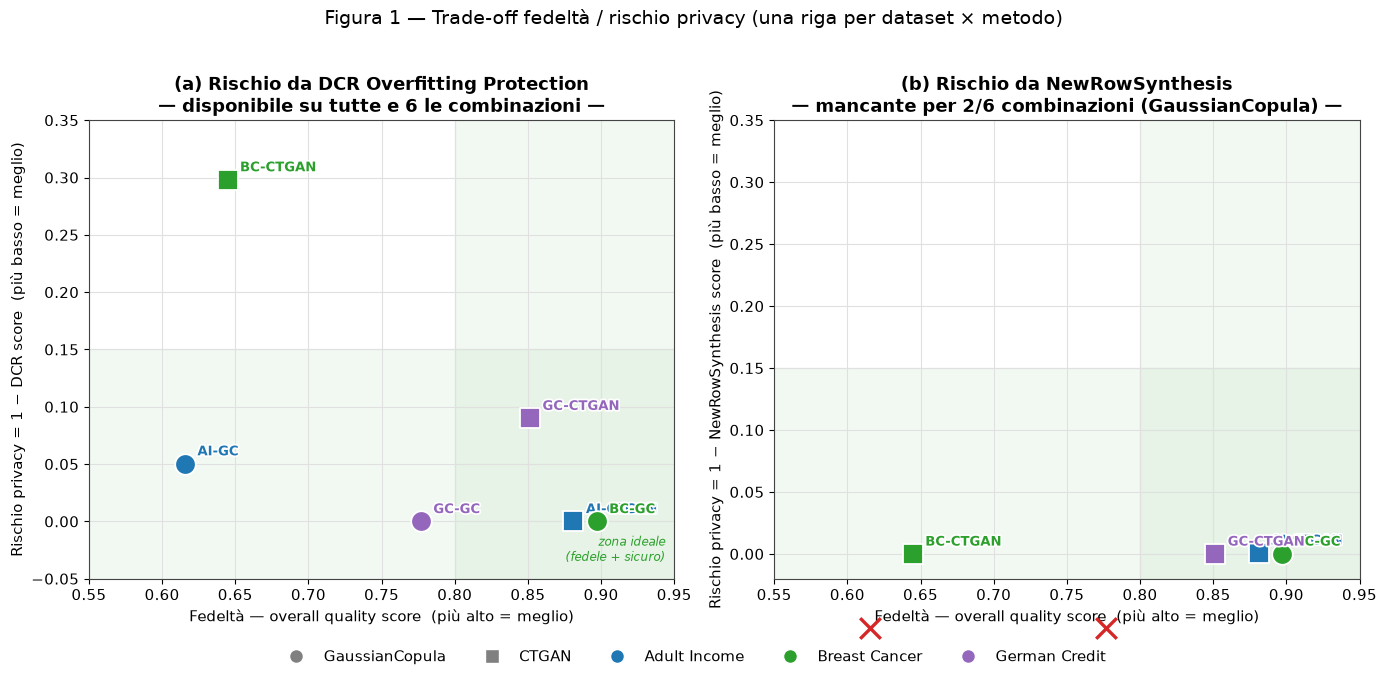

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6.2))

# ---------- pannello sinistro: rischio da DCR (disponibile per tutte le 6 combinazioni) ----------
ax = axes[0]
for _, row in df_unique.iterrows():
    ax.scatter(
        row["overall_quality_score"], row["risk_dcr"],
        s=220, marker=METHOD_MARKERS[row["method"]],
        color=DATASET_COLORS[row["dataset"]],
        edgecolor="white", linewidth=1.3, zorder=3,
    )
    ax.annotate(
        row["combo_label"],
        (row["overall_quality_score"], row["risk_dcr"]),
        textcoords="offset points", xytext=(9, 6), fontsize=9.5, fontweight="bold",
        color=DATASET_COLORS[row["dataset"]],
        path_effects=[pe.withStroke(linewidth=2.5, foreground="white")],
    )

ax.axhspan(-0.05, 0.15, color="#2ca02c", alpha=0.06, zorder=0)
ax.axvspan(0.8, 1.05, color="#2ca02c", alpha=0.06, zorder=0)
ax.text(0.985, 0.03, "zona ideale\n(fedele + sicuro)", transform=ax.transAxes,
        ha="right", va="bottom", fontsize=8.5, style="italic", color="#2ca02c")

ax.set_xlim(0.55, 0.95)
ax.set_ylim(-0.05, 0.35)
ax.set_xlabel("Fedeltà — overall quality score  (più alto = meglio)")
ax.set_ylabel("Rischio privacy = 1 − DCR score  (più basso = meglio)")
ax.set_title("(a) Rischio da DCR Overfitting Protection\n— disponibile su tutte e 6 le combinazioni —")

# ---------- pannello destro: rischio da NRS (solo dove disponibile) ----------
ax = axes[1]
valid = df_unique.dropna(subset=["risk_nrs"])
missing = df_unique[df_unique["risk_nrs"].isna()]

for _, row in valid.iterrows():
    ax.scatter(
        row["overall_quality_score"], row["risk_nrs"],
        s=220, marker=METHOD_MARKERS[row["method"]],
        color=DATASET_COLORS[row["dataset"]],
        edgecolor="white", linewidth=1.3, zorder=3,
    )
    ax.annotate(
        row["combo_label"],
        (row["overall_quality_score"], row["risk_nrs"]),
        textcoords="offset points", xytext=(9, 6), fontsize=9.5, fontweight="bold",
        color=DATASET_COLORS[row["dataset"]],
        path_effects=[pe.withStroke(linewidth=2.5, foreground="white")],
    )

# combinazioni con NRS mancante: mostrate come marker "vuoto" in basso, fuori dagli assi normali
for i, (_, row) in enumerate(missing.iterrows()):
    ax.scatter(
        row["overall_quality_score"], -0.06,
        s=220, marker="x", color="#d62728", linewidth=2.4, zorder=3, clip_on=False,
    )
    ax.annotate(
        f"{row['combo_label']}\n(NRS mancante)",
        (row["overall_quality_score"], -0.06),
        textcoords="offset points", xytext=(0, -22), fontsize=8.5, ha="center",
        color="#d62728", clip_on=False,
    )

ax.axhspan(-0.02, 0.15, color="#2ca02c", alpha=0.06, zorder=0)
ax.axvspan(0.8, 1.05, color="#2ca02c", alpha=0.06, zorder=0)

ax.set_xlim(0.55, 0.95)
ax.set_ylim(-0.02, 0.35)
ax.set_xlabel("Fedeltà — overall quality score  (più alto = meglio)")
ax.set_ylabel("Rischio privacy = 1 − NewRowSynthesis score  (più basso = meglio)")
ax.set_title("(b) Rischio da NewRowSynthesis\n— mancante per 2/6 combinazioni (GaussianCopula) —")

# legenda comune
legend_handles = (
    [plt.Line2D([0], [0], marker="o", linestyle="", markersize=10, markerfacecolor="grey",
                markeredgecolor="white", label="GaussianCopula")]
    + [plt.Line2D([0], [0], marker="s", linestyle="", markersize=10, markerfacecolor="grey",
                  markeredgecolor="white", label="CTGAN")]
    + [plt.Line2D([0], [0], marker="o", linestyle="", markersize=10, markerfacecolor=c,
                  markeredgecolor="white", label=DATASET_LABELS[d]) for d, c in DATASET_COLORS.items()]
)
fig.legend(handles=legend_handles, loc="lower center", ncol=5, frameon=False, bbox_to_anchor=(0.5, -0.06))

fig.suptitle("Figura 1 — Trade-off fedeltà / rischio privacy (una riga per dataset × metodo)", fontsize=14, y=1.02)
fig.tight_layout()
plt.show()


**Lettura della Figura 1.** Se ci fosse un trade-off, i punti disegnerebbero una diagonale ascendente (più fedeltà → più rischio). Non è quello che si osserva nel pannello (a): `breast_cancer/CTGAN` è **sia** poco fedele (0.645) **sia** relativamente più a rischio (DCR 0.70); `adult_income/CTGAN`, `breast_cancer/GaussianCopula` e `german_credit/GaussianCopula` sono invece fedeli **e** a rischio quasi nullo. L'unica combinazione che si avvicina a un trade-off "vero" è `german_credit/CTGAN` (fedeltà più alta di GaussianCopula sullo stesso dataset, ma rischio leggermente più alto: 0.09 vs 0.00). Verifichiamo questa impressione con la correlazione.


In [5]:
def report_correlation(sub_df: pd.DataFrame, risk_col: str, label: str) -> None:
    x = sub_df["overall_quality_score"].to_numpy()
    y = sub_df[risk_col].to_numpy()
    n = len(x)
    if n < 3:
        print(f"{label}: solo {n} punti disponibili, correlazione non calcolata (troppo pochi).")
        return
    r, p = pearsonr(x, y)
    direzione = "POSITIVA (coerente con un trade-off)" if r > 0.2 else (
        "NEGATIVA (fedeltà e sicurezza si muovono insieme, non in trade-off)" if r < -0.2
        else "debole/assente"
    )
    print(f"{label}")
    print(f"  n = {n} combinazioni dataset×metodo")
    print(f"  r di Pearson = {r:+.3f}  (p = {p:.3f})")
    print(f"  interpretazione: correlazione {direzione}")
    print(f"  ⚠️  n è molto piccolo: trattare come indicazione qualitativa, non come stima statistica robusta.")
    print()

print("=" * 78)
report_correlation(df_unique, "risk_dcr", "Fedeltà vs rischio DCR — tutte le 6 combinazioni")
report_correlation(df_unique.dropna(subset=["risk_nrs"]), "risk_nrs",
                    "Fedeltà vs rischio NRS — solo le 4 combinazioni con NRS disponibile")
print("=" * 78)


Fedeltà vs rischio DCR — tutte le 6 combinazioni
  n = 6 combinazioni dataset×metodo
  r di Pearson = -0.582  (p = 0.226)
  interpretazione: correlazione NEGATIVA (fedeltà e sicurezza si muovono insieme, non in trade-off)
  ⚠️  n è molto piccolo: trattare come indicazione qualitativa, non come stima statistica robusta.

Fedeltà vs rischio NRS — solo le 4 combinazioni con NRS disponibile
  n = 4 combinazioni dataset×metodo
  r di Pearson = +0.355  (p = 0.645)
  interpretazione: correlazione POSITIVA (coerente con un trade-off)
  ⚠️  n è molto piccolo: trattare come indicazione qualitativa, non come stima statistica robusta.



## 4. Confronto per dataset e metodo

Un secondo modo di leggere lo stesso fenomeno: invece di uno scatter unico, due barre affiancate per ogni dataset (una per metodo), fedeltà e sicurezza (`1 − rischio`) una accanto all'altra. Se un metodo "vince" su entrambe le barre per un dato dataset, non c'è trade-off in quel caso; se vince su una e perde sull'altra, c'è.


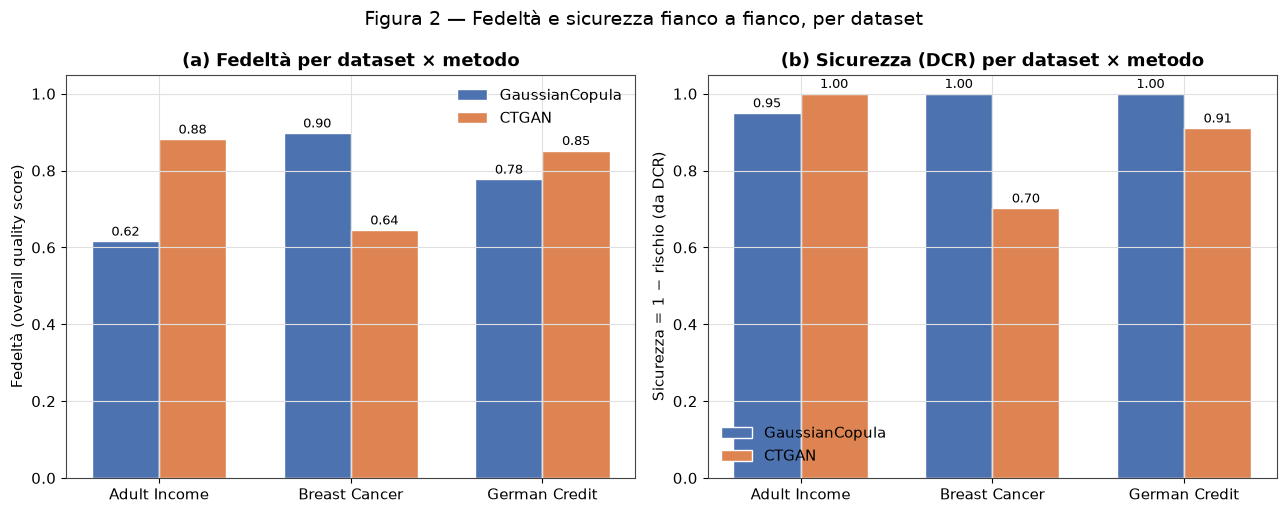

In [6]:
datasets_order = ["adult_income", "breast_cancer", "german_credit"]
methods_order = ["gaussian_copula", "ctgan"]

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), sharey=False)

x = np.arange(len(datasets_order))
width = 0.35

# --- pannello sinistro: fedeltà ---
ax = axes[0]
for i, method in enumerate(methods_order):
    vals = [
        df_unique[(df_unique.dataset == d) & (df_unique.method == method)]["overall_quality_score"].iloc[0]
        for d in datasets_order
    ]
    offset = (i - 0.5) * width
    bars = ax.bar(x + offset, vals, width, label=METHOD_LABELS[method],
                   color=["#4c72b0", "#dd8452"][i], edgecolor="white")
    ax.bar_label(bars, fmt="%.2f", fontsize=9, padding=2)
ax.set_xticks(x)
ax.set_xticklabels([DATASET_LABELS[d] for d in datasets_order])
ax.set_ylim(0, 1.05)
ax.set_ylabel("Fedeltà (overall quality score)")
ax.set_title("(a) Fedeltà per dataset × metodo")
ax.legend(frameon=False)

# --- pannello destro: sicurezza = 1 - rischio DCR ---
ax = axes[1]
for i, method in enumerate(methods_order):
    vals = [
        1 - df_unique[(df_unique.dataset == d) & (df_unique.method == method)]["risk_dcr"].iloc[0]
        for d in datasets_order
    ]
    offset = (i - 0.5) * width
    bars = ax.bar(x + offset, vals, width, label=METHOD_LABELS[method],
                   color=["#4c72b0", "#dd8452"][i], edgecolor="white")
    ax.bar_label(bars, fmt="%.2f", fontsize=9, padding=2)
ax.set_xticks(x)
ax.set_xticklabels([DATASET_LABELS[d] for d in datasets_order])
ax.set_ylim(0, 1.05)
ax.set_ylabel("Sicurezza = 1 − rischio (da DCR)")
ax.set_title("(b) Sicurezza (DCR) per dataset × metodo")
ax.legend(frameon=False)

fig.suptitle("Figura 2 — Fedeltà e sicurezza fianco a fianco, per dataset", fontsize=14)
fig.tight_layout()
plt.show()


**Lettura della Figura 2.** Su `adult_income` e `breast_cancer`, il metodo con fedeltà più alta ha *anche* sicurezza pari o superiore all'altro metodo — nessun trade-off. Su `german_credit`, CTGAN ha fedeltà più alta di GaussianCopula (0.85 vs 0.78) ma sicurezza leggermente inferiore (0.91 vs 1.00): è l'unico caso, tra i sei, in cui guadagnare fedeltà costa qualcosa in sicurezza — ed è comunque un costo piccolo (9 punti percentuali).

## 5. Tabella di sintesi e risposta a RQ2


In [7]:
answer_table = df_unique[[
    "dataset_label", "method_label", "overall_quality_score", "risk_dcr", "risk_nrs"
]].rename(columns={
    "dataset_label": "Dataset",
    "method_label": "Metodo",
    "overall_quality_score": "Fedelta",
    "risk_dcr": "Rischio (DCR)",
    "risk_nrs": "Rischio (NRS)",
}).round(3)

print(answer_table.to_string(index=False))
print()

latex_table = answer_table.to_latex(
    index=False, na_rep="--", float_format="%.3f",
    caption="Fedelta e rischio privacy (DCR, NRS) per dataset e metodo di generazione.",
    label="tab:rq2-fedelta-rischio",
)
print("--- LaTeX pronto per la tesi (tabella) ---")
print(latex_table)


      Dataset         Metodo  Fedelta  Rischio (DCR)  Rischio (NRS)
 Adult Income GaussianCopula    0.616          0.050            NaN
 Adult Income          CTGAN    0.881          0.000          0.001
Breast Cancer GaussianCopula    0.897          0.000          0.000
Breast Cancer          CTGAN    0.645          0.298          0.000
German Credit GaussianCopula    0.777          0.000            NaN
German Credit          CTGAN    0.851          0.090          0.000

--- LaTeX pronto per la tesi (tabella) ---
\begin{table}
\caption{Fedelta e rischio privacy (DCR, NRS) per dataset e metodo di generazione.}
\label{tab:rq2-fedelta-rischio}
\begin{tabular}{llrrr}
\toprule
Dataset & Metodo & Fedelta & Rischio (DCR) & Rischio (NRS) \\
\midrule
Adult Income & GaussianCopula & 0.616 & 0.050 & -- \\
Adult Income & CTGAN & 0.881 & 0.000 & 0.001 \\
Breast Cancer & GaussianCopula & 0.897 & 0.000 & 0.000 \\
Breast Cancer & CTGAN & 0.645 & 0.298 & 0.000 \\
German Credit & GaussianCopula & 0.777

### Risposta a RQ2

Sui dati di questa campagna, **non emerge un trade-off sistematico e netto tra fedeltà e privacy**: nella maggioranza dei casi (4 combinazioni su 6, sia con la metrica DCR sia — dove disponibile — con NRS) fedeltà alta e rischio basso **coesistono**, invece di escludersi a vicenda. L'unica eccezione osservata è `german_credit`, dove CTGAN ottiene più fedeltà di GaussianCopula pagando un rischio DCR leggermente più alto — un trade-off reale ma piccolo, non generalizzabile con un solo dataset che lo mostra.

Questo è compatibile con un'interpretazione ingegneristica più che statistica: *quando* un synthesizer riesce a modellare bene le distribuzioni del dataset (fedeltà alta), spesso lo fa catturando pattern statistici generali della popolazione, non copiando record specifici — per questo fedeltà e privacy non sono necessariamente in conflitto. Il caso in cui *sono* in conflitto (`breast_cancer/CTGAN`, fedeltà **e** sicurezza basse insieme) sembra piuttosto un fallimento congiunto del metodo su un dataset piccolo (455 righe di train), coerente con quanto osservato per RQ1 (CTGAN perde nettamente su Breast Cancer, il dataset più piccolo e interamente numerico).

**Va però letta con cautela**, per i limiti elencati sotto: il campione è di sole 6 combinazioni indipendenti, un terzo delle misure di rischio (NRS su GaussianCopula) è strutturalmente assente, e la fedeltà di `adult_income` non è stabile tra sessioni diverse.

## 6. Limiti di questa analisi

- **n molto piccolo.** Solo 6 combinazioni dataset × metodo indipendenti (le repliche CTGAN, bit-identiche, non aggiungono informazione — vedi §2). Qualsiasi correlazione o pattern va letto come indicazione qualitativa, non come stima statisticamente robusta: con n=6 anche un singolo punto atipico (`breast_cancer/CTGAN`) pesa moltissimo sul risultato complessivo.
- **NRS strutturalmente mancante per GaussianCopula su 2 dataset su 3.** Non è un caso isolato di German Credit (come si pensava dopo la campagna del 19 settembre): compare anche su Adult Income. La causa probabile è che `sanitize_reserved_keyword_values` viene applicata solo al dataframe reale in fase di ingestion, mai al dataframe sintetico — quindi un valore "pericoloso" ricampionato da GaussianCopula non viene mai sanificato prima del calcolo NRS (`STATO_PROGETTO.md` §8.3, §13.2). Finché questo non viene corretto nel codice, il confronto NRS tra i due metodi resta strutturalmente sbilanciato a sfavore di GaussianCopula — non perché GaussianCopula sia davvero "più rischioso" su questa metrica, ma perché la metrica stessa non riesce a essere calcolata per lui.
- **Fedeltà di `adult_income` instabile tra sessioni.** `overall_quality_score` per `adult_income/gaussian_copula` era 0.806 nella campagna storica del 19 settembre e 0.616 in questa campagna (26 settembre), a parità di seed e codice dichiarati (`STATO_PROGETTO.md` §13.3). L'ipotesi più probabile è che l'ingestion da OpenML non garantisca lo stesso ordine di riga a ogni fetch, cambiando di fatto il train set nonostante il seed sia fissato. Il punto nella Figura 1 relativo a questa combinazione va quindi considerato meno affidabile degli altri finché il problema non è verificato e, se confermato, risolto (congelando una copia CSV locale del dataset).
- **DCR Overfitting Protection ora disponibile, ma solo da questa campagna.** Nei 12 run storici del 19 settembre, `dcr_score` era sempre `null` per un bug di compatibilità con la versione di `sdmetrics` installata (`STATO_PROGETTO.md` §8.1); qui invece funziona su tutte le run. Prima di scrivere in tesi che "DCR è disponibile", va congelata la versione di `sdmetrics` usata in questa campagna (`requirements.lock.txt`), altrimenti un rilancio futuro potrebbe silenziosamente tornare a fallire.
- **Repliche disponibili solo per CTGAN.** GaussianCopula ha una sola run per dataset in questi dati: non è possibile verificare empiricamente, con questa campagna, se anche il suo rischio privacy sia stabile a seed fisso (per la fedeltà e la riproducibilità dell'hash sì, vedi notebook RQ3).

### Prossimi passi consigliati prima di finalizzare questi numeri in tesi

1. Estendere `sanitize_reserved_keyword_values` anche al dataframe sintetico, per rendere NRS calcolabile su tutte le combinazioni (non solo 4/6).
2. Verificare la stabilità dell'ingestion OpenML (hash del CSV grezzo tra due fetch separati) prima di dichiarare "riproducibilità bit-a-bit" nella Discussione di RQ3, dato che la stessa instabilità sembra spiegare anche i salti di fedeltà osservati qui.
3. Congelare `requirements.lock.txt` con la versione di `sdmetrics` che ha prodotto questa campagna, per non perdere di nuovo `dcr_score` in un rilancio futuro.
4. Se possibile, ripetere anche GaussianCopula su più repliche (è economico, secondi di fit) per poter controllare la stabilità del suo rischio privacy così come già si fa per CTGAN.
